<a href="https://colab.research.google.com/github/aicoder243/lastname100-/blob/main/Copy_of_Kaggle_K_Means_Hierarchical_PCA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

https://www.kaggle.com/datasets/simtoor/mall-customers

In [ ]:

from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd
df=pd.read_csv ('/content/drive/MyDrive/DATASETS/Winerecognitionclean.csv')
print(df.head(0))

Empty DataFrame
Columns: [alcohol, malic_acid, ash, alcalinity_of_ash, magnesium, total_phenols, flavanoids, nonflavanoid_phenols, proanthocyanins, color_intensity, hue, od280/od315_of_diluted_wines, proline, target]
Index: []



Selected Features:
   flavanoids   hue  proline
0        3.06  1.04   1065.0
1        2.76  1.05   1050.0
2        3.24  1.03   1185.0
3        3.49  0.86   1480.0
4        2.69  1.04    735.0

K-Means Results:
   alcohol   ash  magnesium  flavanoids   hue  proline  KMeans_Cluster
0    14.23  2.43      127.0        3.06  1.04   1065.0               0
1    13.20  2.14      100.0        2.76  1.05   1050.0               0
2    13.16  2.67      101.0        3.24  1.03   1185.0               4
3    14.37  2.50      113.0        3.49  0.86   1480.0               4
4    13.24  2.87      118.0        2.69  1.04    735.0               0
5    14.20  2.45      112.0        3.39  1.05   1450.0               4
6    14.39  2.45       96.0        2.52  1.02   1290.0               4
7    14.06  2.61      121.0        2.51  1.06   1295.0               4
8    14.83  2.17       97.0        2.98  1.08   1045.0               0
9    13.86  2.27       98.0        3.15  1.01   1045.0               0


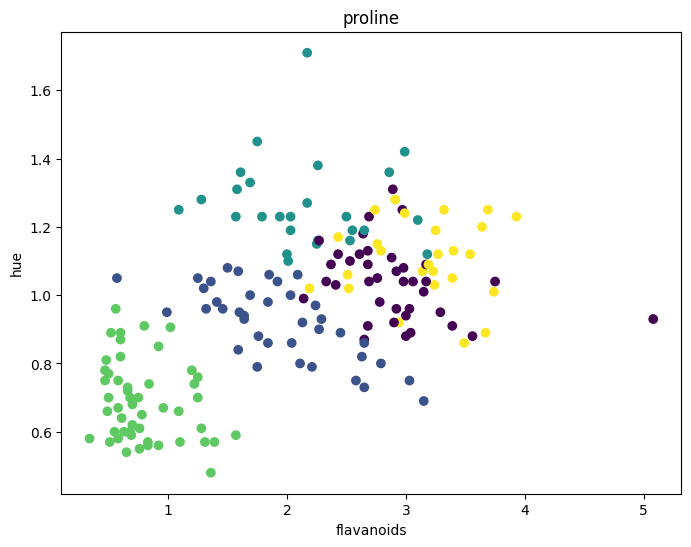


Explained Variance:
[0.62058138 0.25505131]

Total Variance Explained:
0.8756326908038548


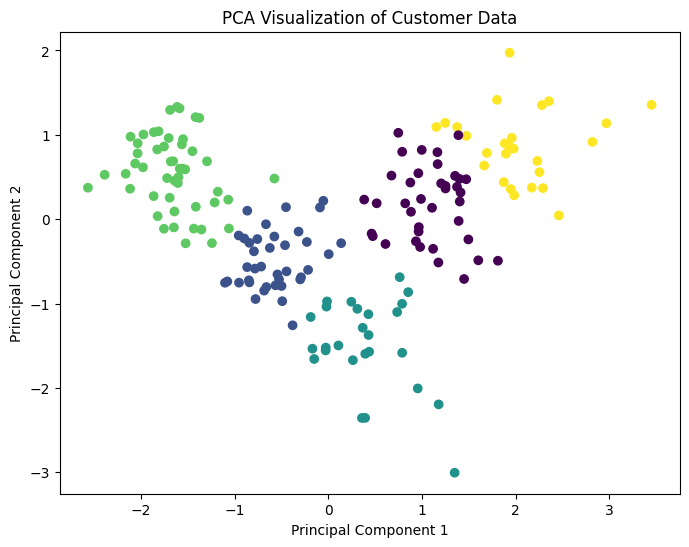

In [ ]:
# ============================================
# K-Means, Hierarchical Clustering, and PCA
# Kaggle Mall Customers Dataset
# ============================================

# 1. Import libraries
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import drive

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.cluster import AgglomerativeClustering
from sklearn.decomposition import PCA


# ============================================
# 4. Select features
# ============================================

X = df[
    [
        'flavanoids',
        'hue',
        'proline'
    ]
]

print("\nSelected Features:")
print(X.head())


# ============================================
# 5. Standardize the data
# ============================================

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)


# ============================================
# 6. K-MEANS CLUSTERING
# ============================================

kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

df['KMeans_Cluster'] = kmeans.fit_predict(X_scaled)


print("\nK-Means Results:")
print(df[
    [
        'alcohol',
        'ash',
        'magnesium',
        'flavanoids',
        'hue',
        'proline',
        'KMeans_Cluster'

    ]
].head(10))


# ============================================
# 7. Plot K-Means
# ============================================

plt.figure(figsize=(8, 6))

plt.scatter(
    df['flavanoids'],
    df['hue'],
    c=df['KMeans_Cluster']
)

plt.xlabel('flavanoids')
plt.ylabel('hue')
plt.title('proline')

plt.show()

# plt.figure(figsize=(8, 6))

# plt.scatter(
#     df['Annual Income (k$)'],
#     df['Spending Score (1-100)'],
#     c=df['KMeans_Cluster']
# )

# plt.xlabel('Annual Income (k$)')
# plt.ylabel('Spending Score (1-100)')
# plt.title('K-Means Customer Clusters')

# plt.show()









# ============================================
# 10. PCA
# ============================================

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)


# Add PCA results to DataFrame
df['PC1'] = X_pca[:, 0]
df['PC2'] = X_pca[:, 1]


# ============================================
# 11. Explained Variance
# ============================================

print("\nExplained Variance:")
print(pca.explained_variance_ratio_)

print("\nTotal Variance Explained:")
print(pca.explained_variance_ratio_.sum())


# ============================================
# 12. Plot PCA
# ============================================

plt.figure(figsize=(8, 6))

plt.scatter(
    df['PC1'],
    df['PC2'],
    c=df['KMeans_Cluster']
)

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('PCA Visualization of Customer Data')

plt.show()



# 1. Import Libraries
# My Notes


```python
import pandas as pd
```

Imports **Pandas**, which we use to read and work with the dataset.

```python
import matplotlib.pyplot as plt
```

Imports **Matplotlib**, which we use to create the plots.

```python
from google.colab import drive
```

Imports the Google Colab tool that allows us to connect Colab to **Google Drive**.

```python
from sklearn.preprocessing import StandardScaler
```

Imports `StandardScaler`, which standardizes the numerical features.

```python
from sklearn.cluster import KMeans
```

Imports the **K-Means clustering algorithm**.

```python
from sklearn.cluster import AgglomerativeClustering
```

Imports **Hierarchical Clustering**.

```python
from sklearn.decomposition import PCA
```

Imports **Principal Component Analysis (PCA)**.

---

# 2. Mount Google Drive

```python
drive.mount('/content/drive')
```

This connects Google Colab to your Google Drive.

After running this line, Colab will ask you to authorize access.

Once connected, your Drive can be accessed through:

```text
/content/drive/
```

For example:

```text
My Drive
   ↓
ML_Datasets
   ↓
Mall_Customers.csv
```

---

# 3. Read the Kaggle Dataset

```python
file_path = '/content/drive/MyDrive/ML_Datasets/Mall_Customers.csv'
```

Stores the location of the CSV file in a variable called `file_path`.

Instead of repeatedly writing the entire path, we can simply use:

```python
file_path
```

---

```python
df = pd.read_csv(file_path)
```

This reads the CSV file and stores it as a Pandas DataFrame called `df`.

Think of `df` as our **data table**.

---

```python
print("First 5 rows:")
print(df.head())
```

`head()` displays the first five rows of the dataset.

This is useful for checking whether the dataset loaded correctly.

---

# 4. Select the Features

The dataset contains several columns.

We select three:

```python
X = df[
    [
        'Age',
        'Annual Income (k$)',
        'Spending Score (1-100)'
    ]
]
```

These become our **input features**.

We are asking:

> Can we identify groups of customers based on their age, income, and spending behavior?

So:

```text
X =
Age
Annual Income
Spending Score
```

---

```python
print("\nSelected Features:")
print(X.head())
```

Displays the first five rows of the selected features.

---

# 5. Standardize the Data

```python
scaler = StandardScaler()
```

Creates a standardization object.

Why do we need this?

Consider:

```text
Age              → approximately 18–70
Annual Income    → approximately 15–137
Spending Score   → approximately 1–100
```

These features have different ranges.

---

```python
X_scaled = scaler.fit_transform(X)
```

This standardizes all three features.

The basic idea is:

```text
Original Data
      ↓
StandardScaler
      ↓
Scaled Data
```

The features are transformed so that they are on a comparable scale.

This is particularly important for **distance-based algorithms such as K-Means**.

---

# 6. K-Means Clustering

```python
kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)
```

Creates a K-Means model.

### `n_clusters=5`

We are asking K-Means to create **5 groups**.

```text
Customers
    ↓
 ┌──┬──┬──┬──┬──┐
 C1 C2 C3 C4 C5
```

### `random_state=42`

K-Means uses some random initialization.

Setting `random_state=42` helps us get reproducible results.

### `n_init=10`

K-Means tries different starting centroid positions and chooses a good solution.

---

```python
df['KMeans_Cluster'] = kmeans.fit_predict(X_scaled)
```

This is one of the most important lines.

### `fit`

K-Means learns the cluster structure.

### `predict`

It assigns each customer to a cluster.

### `fit_predict`

Does both at once.

A new column is added:

```text
KMeans_Cluster
```

For example:

```text
Customer 1 → Cluster 2
Customer 2 → Cluster 2
Customer 3 → Cluster 0
Customer 4 → Cluster 4
```

The numbers are simply **cluster labels**.

Cluster `0` does not necessarily mean "best" or "lowest."

---

# 7. Display K-Means Results

```python
print("\nK-Means Results:")
```

Prints a heading.

```python
print(df[
    [
        'CustomerID',
        'Age',
        'Annual Income (k$)',
        'Spending Score (1-100)',
        'KMeans_Cluster'
    ]
].head(10))
```

Displays the first 10 customers along with their assigned cluster.

The result might look conceptually like:

| Customer | Age | Income | Spending | Cluster |
|---|---:|---:|---:|---:|
| 1 | 19 | 15 | 39 | 3 |
| 2 | 21 | 15 | 81 | 1 |
| 3 | 20 | 16 | 6 | 4 |

---

# 8. K-Means Plot

```python
plt.figure(figsize=(8, 6))
```

Creates a figure that is 8 × 6 inches.

---

```python
plt.scatter(
    df['Annual Income (k$)'],
    df['Spending Score (1-100)'],
    c=df['KMeans_Cluster']
)
```

Creates a scatter plot.

### X-axis

```python
df['Annual Income (k$)']
```

Income is placed on the x-axis.

### Y-axis

```python
df['Spending Score (1-100)']
```

Spending score is placed on the y-axis.

### `c=`

```python
c=df['KMeans_Cluster']
```

Uses the cluster assignment to visually distinguish the groups.

So we can visually see the customer segments.

---

```python
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
```

Adds labels to the axes.

```python
plt.title('K-Means Customer Clusters')
```

Adds the graph title.

```python
plt.show()
```

Displays the graph.

---

# 9. Hierarchical Clustering

Now we perform a **different clustering technique on the same data**.

```python
hierarchical = AgglomerativeClustering(
    n_clusters=5
)
```

Creates a hierarchical clustering model.

Again, we ask for:

```text
5 clusters
```

The important difference is how the groups are created.

### K-Means

```text
Start with centroids
      ↓
Assign points
      ↓
Update centroids
      ↓
Repeat
```

### Hierarchical

```text
Start with individual points
      ↓
Find similar points
      ↓
Merge them
      ↓
Continue merging
      ↓
Create groups
```

---

```python
df['Hierarchical_Cluster'] = hierarchical.fit_predict(
    X_scaled
)
```

The algorithm learns the clusters and assigns every customer to one.

A new column is created:

```text
Hierarchical_Cluster
```

---

# 10. Display Hierarchical Results

```python
print("\nHierarchical Clustering Results:")
```

Prints a heading.

```python
print(df[
    [
        'CustomerID',
        'Age',
        'Annual Income (k$)',
        'Spending Score (1-100)',
        'Hierarchical_Cluster'
    ]
].head(10))
```

Displays the first 10 customers and their hierarchical cluster assignments.

---

# 11. Hierarchical Plot

```python
plt.figure(figsize=(8, 6))
```

Creates the figure.

```python
plt.scatter(
    df['Annual Income (k$)'],
    df['Spending Score (1-100)'],
    c=df['Hierarchical_Cluster']
)
```

Creates a scatter plot.

This time the points are distinguished using:

```python
Hierarchical_Cluster
```

---

```python
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title('Hierarchical Customer Clusters')
plt.show()
```

Adds labels, title, and displays the graph.

---

# 12. PCA

Now we move from **clustering** to **dimensionality reduction**.

```python
pca = PCA(n_components=2)
```

Creates a PCA model.

We are saying:

> Take our three features and reduce them to two dimensions.

Originally:

```text
Age
Income
Spending
```

After PCA:

```text
PC1
PC2
```

---

```python
X_pca = pca.fit_transform(X_scaled)
```

PCA learns the important directions of variation and transforms the data.

The resulting data is stored in:

```text
X_pca
```

---

# 13. Add PCA Results to Dataset

```python
df['PC1'] = X_pca[:, 0]
```

Creates a new column called `PC1`.

`[:, 0]` means:

> Take every row from the first PCA column.

---

```python
df['PC2'] = X_pca[:, 1]
```

Creates a second column called `PC2`.

Now the DataFrame contains:

```text
Age
Income
Spending
PC1
PC2
```

---

# 14. Explained Variance

```python
print("\nExplained Variance:")
```

Prints a heading.

```python
print(pca.explained_variance_ratio_)
```

Shows how much variation in the original data is captured by each principal component.

For example, imagine the result is:

```text
[0.45, 0.32]
```

That means:

```text
PC1 → 45%
PC2 → 32%
```

Together:

```text
45% + 32% = 77%
```

So our two PCA dimensions capture **77% of the variation** in the original three features.

---

```python
print("\nTotal Variance Explained:")
print(pca.explained_variance_ratio_.sum())
```

Adds the two percentages together.

This tells us how much total information/variation is retained by PC1 and PC2.

---

# 15. PCA Plot

```python
plt.figure(figsize=(8, 6))
```

Creates the figure.

---

```python
plt.scatter(
    df['PC1'],
    df['PC2'],
    c=df['KMeans_Cluster']
)
```

Creates a scatter plot where:

**X-axis:**

```text
PC1
```

**Y-axis:**

```text
PC2
```

The points are colored according to the **K-Means cluster**.

This is useful because PCA has reduced our three-dimensional dataset to two dimensions, allowing us to visualize it.

---

```python
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('PCA Visualization of Customer Data')
plt.show()
```

Adds the labels and displays the graph.

---



